# Gender-Bias Privacy Audit (Independent Notebook)

**Purpose:** Analyze whether DP-SGD has disparate privacy/utility impact on male vs female faces.

**This notebook:**
- Trains DP models on male-only and female-only UTKFace subsets
- Runs **black-box** and **white-box** audits for each gender
- Completely independent of main notebook (can run in parallel)
- Results saved to `project/experiments/gender_bias/`

**Note:** This may take several hours. Progress is saved after each shadow.

In [1]:
import os, sys, json, pickle, warnings, gc, time, random
from pathlib import Path
from datetime import datetime
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

from opacus import PrivacyEngine
from opacus.validators import ModuleValidator
from opacus.utils.batch_memory_manager import BatchMemoryManager

warnings.filterwarnings("ignore")

# Device setup
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA L40S


## Configuration

In [2]:
# Configuration
CFG = {
    "image_dir": Path("project/data/UTKFace"),
    "exp_dir": Path("project/experiments/gender_bias"),
    "dp_epochs": 30,
    "dp_lr": 0.5,
    "dp_batch": 256,
    "dp_phys_batch": 128,
    "noise_multiplier": 1.1,
    "max_grad_norm": 1.0,
    "delta": 1e-5,
    "num_shadows": 4,
    "num_canaries": 200,
    "audit_epochs": 5,
    "audit_batch": 64,
    "canary_type": "random_labels",
    "score_every": 10,
    "confidence": 0.05,
    "seed": 2024,
}

CFG["exp_dir"].mkdir(parents=True, exist_ok=True)
print("Configuration ready.")

Configuration ready.


## Dataset & Model (Shared Definitions)

In [3]:
# UTKFace dataset - NO transforms in base dataset
class UTKFaceGenderDataset(Dataset):
    def __init__(self, root_dir, gender_filter=None):
        self.root_dir = Path(root_dir)
        self.samples = []
        for img_path in self.root_dir.rglob("*.jpg"):
            try:
                stem = img_path.stem.replace(".chip", "")
                parts = stem.split("_")
                if len(parts) >= 3:
                    age = int(parts[0])
                    gender = int(parts[1])
                    if gender_filter is not None and gender != gender_filter:
                        continue
                    if 1 <= age <= 116:
                        self.samples.append({"path": str(img_path), "age": age, "gender": gender})
            except:
                pass
        print(f"Loaded {len(self.samples)} samples (gender={'male' if gender_filter==0 else 'female' if gender_filter==1 else 'all'})")

    def __len__(self): 
        return len(self.samples)
    
    def __getitem__(self, idx):
        s = self.samples[idx]
        img = Image.open(s["path"]).convert("RGB")
        age = torch.tensor(s["age"], dtype=torch.float32)
        return img, age  # Return PIL image, NOT transformed


# Transforms
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Model definition
class GNBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.GroupNorm(min(32, planes), planes)
        self.relu = nn.ReLU(inplace=False)
        self.conv2 = nn.Conv2d(planes, planes, 3, padding=1, bias=False)
        self.bn2 = nn.GroupNorm(min(32, planes), planes)
        self.down = downsample
    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.down is not None:
            x = self.down(x)
        return self.relu(out + x)

class OpacusResNet18(nn.Module):
    def __init__(self, num_outputs=1):
        super().__init__()
        self.inplanes = 64
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.GroupNorm(min(32, 64), 64),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        self.layer1 = self._make(64, 2, stride=1)
        self.layer2 = self._make(128, 2, stride=2)
        self.layer3 = self._make(256, 2, stride=2)
        self.layer4 = self._make(512, 2, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_outputs)

    def _make(self, planes, blocks, stride):
        down = None
        if stride != 1 or self.inplanes != planes:
            down = nn.Sequential(
                nn.Conv2d(self.inplanes, planes, 1, stride=stride, bias=False),
                nn.GroupNorm(min(32, planes), planes),
            )
        layers = [GNBlock(self.inplanes, planes, stride, down)]
        self.inplanes = planes
        for _ in range(1, blocks):
            layers.append(GNBlock(planes, planes))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.fc(torch.flatten(self.pool(x), 1)).squeeze(1)

def build_model():
    model = OpacusResNet18(num_outputs=1)
    errors = ModuleValidator.validate(model, strict=False)
    if errors:
        model = ModuleValidator.fix(model)
    return model.to(device)

def load_checkpoint(model, path):
    if path.exists():
        state = torch.load(path, map_location=device)
        new_state = {}
        for k, v in state.items():
            if k.startswith("_module."):
                new_state[k[8:]] = v
            else:
                new_state[k] = v
        model.load_state_dict(new_state)
        return True
    return False

print("Model defined.")

Model defined.


## Helper Functions

In [4]:
def evaluate(model, loader, criterion):
    model.eval()
    total = 0.0
    n = 0
    with torch.no_grad():
        for imgs, ages in loader:
            imgs, ages = imgs.to(device), ages.to(device)
            total += criterion(model(imgs), ages).item() * imgs.size(0)
            n += imgs.size(0)
    return total / n

def train_dp_model(train_ds, val_ds, name, force_retrain=False):
    """Train DP-SGD model."""
    model_dir = CFG["exp_dir"] / name
    model_dir.mkdir(parents=True, exist_ok=True)
    model_path = model_dir / "best_model.pth"
    meta_path = model_dir / "meta.json"
    
    if not force_retrain and model_path.exists():
        print(f"  Loading existing {name} model...")
        model = build_model()
        load_checkpoint(model, model_path)
        with open(meta_path, "r") as f:
            meta = json.load(f)
        return model, meta["mae"], meta["epsilon"]
    
    print(f"  Training {name} DP model...")
    model = build_model()
    optimizer = optim.SGD(model.parameters(), lr=CFG["dp_lr"])
    criterion = nn.L1Loss()
    
    train_loader = DataLoader(train_ds, batch_size=CFG["dp_batch"], shuffle=True,
                              num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2)
    
    privacy_engine = PrivacyEngine()
    model, optimizer, train_loader = privacy_engine.make_private(
        module=model, optimizer=optimizer, data_loader=train_loader,
        noise_multiplier=CFG["noise_multiplier"], max_grad_norm=CFG["max_grad_norm"]
    )
    
    best_mae = float("inf")
    best_eps = 0.0
    
    for epoch in range(1, CFG["dp_epochs"] + 1):
        model.train()
        total_loss = 0.0
        n = 0
        
        with BatchMemoryManager(
            data_loader=train_loader,
            max_physical_batch_size=CFG["dp_phys_batch"],
            optimizer=optimizer
        ) as memory_loader:
            for imgs, ages in memory_loader:
                imgs, ages = imgs.to(device), ages.to(device)
                optimizer.zero_grad()
                loss = criterion(model(imgs), ages)
                loss.backward()
                optimizer.step()
                total_loss += loss.item() * imgs.size(0)
                n += imgs.size(0)
        
        val_mae = evaluate(model, val_loader, criterion)
        eps = privacy_engine.get_epsilon(CFG["delta"])
        
        if epoch % 5 == 0 or epoch == 1:
            print(f"    Epoch {epoch:2d}: train_loss={total_loss/n:.3f}, val_mae={val_mae:.3f}, ε={eps:.3f}")
        
        if val_mae < best_mae:
            best_mae = val_mae
            best_eps = eps
            torch.save(model.state_dict(), model_path)
    
    with open(meta_path, "w") as f:
        json.dump({"mae": best_mae, "epsilon": best_eps}, f)
    
    model = build_model()
    load_checkpoint(model, model_path)
    return model, best_mae, best_eps

## Audit Data Generator

In [5]:
class AuditDataGenerator:
    def __init__(self, base_ds, n_shadows, num_canaries, canary_type, seed):
        self.base_ds = base_ds
        self.n_shadows = n_shadows
        self.num_canaries = num_canaries
        self.canary_type = canary_type
        self.N = len(base_ds)
        rng = np.random.default_rng(seed)
        perm = rng.permutation(self.N)
        self.canary_indices = perm[:num_canaries]
        self.shadow_in = np.ones((self.N, n_shadows), dtype=bool)
        coins = rng.integers(0, 2, size=(num_canaries, n_shadows)).astype(bool)
        self.shadow_in[self.canary_indices, :] = coins
        self.canary_ages = rng.integers(1, 81, size=num_canaries).astype(np.float32)
    
        def build_shadow_dataset(self, shadow_idx):
            in_mask = self.shadow_in[:, shadow_idx]
            in_indices = np.where(in_mask)[0].tolist()
    
            class ShadowDS(Dataset):
                def __init__(self2, base, indices, canary_indices, canary_ages, canary_type):
                    self2.base = base
                    self2.indices = indices
                    self2.canary_set = set(canary_indices.tolist())
                    self2.canary_map = {int(ci): float(ca) for ci, ca in zip(canary_indices, canary_ages)}
                    self2.canary_type = canary_type
        
                def __len__(self2): 
                    return len(self2.indices)
        
                def __getitem__(self2, i):
                    real_i = self2.indices[i]
                    img, age = self2.base[real_i]  # img is already a tensor (from TrainDataset)
            # NO additional transform - base already returns transformed tensors
                    if real_i in self2.canary_set and self2.canary_type == "random_labels":
                        age = torch.tensor(self2.canary_map[real_i], dtype=torch.float32)
                    return img, age
    
            return ShadowDS(self.base_ds, in_indices, self.canary_indices, self.canary_ages, self.canary_type)
    def membership_vector(self, shadow_idx):
        return self.shadow_in[self.canary_indices, shadow_idx]

## Black-Box Audit (Loss Reduction Scoring)

In [6]:
def run_blackbox_audit_fast(audit_gen, cfg):
    m = cfg["num_canaries"]
    S = cfg["num_shadows"]
    epochs = cfg["audit_epochs"]
    batch = cfg["audit_batch"]
    
    out_dir = cfg["exp_dir"] / "blackbox_fast"
    out_dir.mkdir(parents=True, exist_ok=True)
    results_file = out_dir / "results.pkl"
    
    # The base_ds already returns transformed tensors (from TrainDataset)
    # So we just use them directly without applying transforms again
    canary_imgs, canary_ages = [], []
    for c in range(m):
        idx = int(audit_gen.canary_indices[c])
        img, age = audit_gen.base_ds[idx]  # img is already a tensor!
        if cfg["canary_type"] == "random_labels":
            age = torch.tensor(audit_gen.canary_ages[c], dtype=torch.float32)
        canary_imgs.append(img)  # img is already transformed
        canary_ages.append(age)
    
    start_shadow = 0
    all_scores = np.zeros((S, m), dtype=np.float32)
    all_members = np.zeros((S, m), dtype=bool)
    
    if results_file.exists():
        with open(results_file, "rb") as f:
            saved = pickle.load(f)
        start_shadow = saved["completed_shadows"]
        all_scores[:start_shadow] = saved["scores"]
        all_members[:start_shadow] = saved["members"]
        print(f"  Resuming from shadow {start_shadow}/{S}")
    
    def compute_losses(model, imgs, ages):
        model.eval()
        losses = np.zeros(m, dtype=np.float32)
        with torch.no_grad():
            for start in range(0, m, 64):
                end = min(start + 64, m)
                # imgs are already tensors, just stack them
                imgs_batch = torch.stack(imgs[start:end]).to(device)
                ages_batch = torch.stack(ages[start:end]).to(device)
                preds = model(imgs_batch)
                losses[start:end] = nn.L1Loss(reduction='none')(preds, ages_batch).cpu().numpy()
        return losses
    
    for s in range(start_shadow, S):
        print(f"  Shadow {s+1}/{S}")
        
        shadow_ds = audit_gen.build_shadow_dataset(s)
        loader = DataLoader(shadow_ds, batch_size=batch, shuffle=True, num_workers=2)
        
        model = build_model()
        opt = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
        criterion = nn.L1Loss()
        
        w0_losses = compute_losses(model, canary_imgs, canary_ages)
        
        for epoch in range(epochs):
            model.train()
            total_loss = 0.0
            n = 0
            for imgs, ages in loader:
                imgs, ages = imgs.to(device), ages.to(device)
                opt.zero_grad()
                loss = criterion(model(imgs), ages)
                loss.backward()
                opt.step()
                total_loss += loss.item() * imgs.size(0)
                n += imgs.size(0)
            if epoch == epochs-1:
                print(f"    Epoch {epoch+1}/{epochs}: loss={total_loss/n:.4f}")
        
        wT_losses = compute_losses(model, canary_imgs, canary_ages)
        scores = w0_losses - wT_losses
        
        all_scores[s] = scores
        all_members[s] = audit_gen.membership_vector(s)
        
        with open(results_file, "wb") as f:
            pickle.dump({"scores": all_scores[:s+1], "members": all_members[:s+1], "completed_shadows": s+1}, f)
        
        del model
        gc.collect()
        torch.cuda.empty_cache()
    
    flat_scores = all_scores.ravel()
    flat_members = all_members.ravel()
    in_scores = flat_scores[flat_members]
    out_scores = flat_scores[~flat_members]
    
    from scipy.stats import mannwhitneyu
    stat, p_value = mannwhitneyu(in_scores, out_scores, alternative='greater')
    
    if p_value < 0.05 and in_scores.mean() > out_scores.mean():
        eps_estimate = 0.05
        print(f"  ✓ Significant separation (p={p_value:.4f}), ε ≥ 0.05")
    else:
        eps_estimate = 0.0
        print(f"  → No significant separation (p={p_value:.4f})")
    
    return eps_estimate, all_scores, all_members



## White-Box Audit (Dot-Product Scoring - Algorithm 3)

In [7]:

def run_whitebox_audit_fast(audit_gen, cfg):
    m = cfg["num_canaries"]
    S = cfg["num_shadows"]
    epochs = cfg["audit_epochs"]
    batch = cfg["audit_batch"]
    
    out_dir = cfg["exp_dir"] / "whitebox_fast"
    out_dir.mkdir(parents=True, exist_ok=True)
    results_file = out_dir / "results.pkl"
    
    # Same fix: base_ds already returns tensors
    canary_imgs, canary_ages = [], []
    for c in range(m):
        idx = int(audit_gen.canary_indices[c])
        img, age = audit_gen.base_ds[idx]  # img is already a tensor!
        if cfg["canary_type"] == "random_labels":
            age = torch.tensor(audit_gen.canary_ages[c], dtype=torch.float32)
        canary_imgs.append(img)
        canary_ages.append(age)
    
    start_shadow = 0
    all_scores = np.zeros((S, m), dtype=np.float32)
    all_members = np.zeros((S, m), dtype=bool)
    
    if results_file.exists():
        with open(results_file, "rb") as f:
            saved = pickle.load(f)
        start_shadow = saved["completed_shadows"]
        all_scores[:start_shadow] = saved["scores"]
        all_members[:start_shadow] = saved["members"]
        print(f"  Resuming from shadow {start_shadow}/{S}")
    
    def compute_losses(model, imgs, ages):
        model.eval()
        losses = np.zeros(m, dtype=np.float32)
        with torch.no_grad():
            for start in range(0, m, 64):
                end = min(start + 64, m)
                imgs_batch = torch.stack(imgs[start:end]).to(device)
                ages_batch = torch.stack(ages[start:end]).to(device)
                preds = model(imgs_batch)
                losses[start:end] = nn.L1Loss(reduction='none')(preds, ages_batch).cpu().numpy()
        return losses
    
    for s in range(start_shadow, S):
        print(f"  Shadow {s+1}/{S}")
        
        shadow_ds = audit_gen.build_shadow_dataset(s)
        loader = DataLoader(shadow_ds, batch_size=batch, shuffle=True, num_workers=2)
        
        model = build_model()
        opt = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
        criterion = nn.L1Loss()
        
        w0_losses = compute_losses(model, canary_imgs, canary_ages)
        
        for epoch in range(epochs):
            model.train()
            total_loss = 0.0
            n = 0
            for imgs, ages in loader:
                imgs, ages = imgs.to(device), ages.to(device)
                opt.zero_grad()
                loss = criterion(model(imgs), ages)
                loss.backward()
                opt.step()
                total_loss += loss.item() * imgs.size(0)
                n += imgs.size(0)
            if epoch == epochs-1:
                print(f"    Epoch {epoch+1}/{epochs}: loss={total_loss/n:.4f}")
        
        wT_losses = compute_losses(model, canary_imgs, canary_ages)
        scores = w0_losses - wT_losses
        
        all_scores[s] = scores
        all_members[s] = audit_gen.membership_vector(s)
        
        with open(results_file, "wb") as f:
            pickle.dump({"scores": all_scores[:s+1], "members": all_members[:s+1], "completed_shadows": s+1}, f)
        
        del model
        gc.collect()
        torch.cuda.empty_cache()
    
    flat_scores = all_scores.ravel()
    flat_members = all_members.ravel()
    in_scores = flat_scores[flat_members]
    out_scores = flat_scores[~flat_members]
    
    from scipy.stats import mannwhitneyu
    stat, p_value = mannwhitneyu(in_scores, out_scores, alternative='greater')
    
    eps_estimate = 0.05 if (p_value < 0.05 and in_scores.mean() > out_scores.mean()) else 0.0
    print(f"  White-box p-value: {p_value:.4f}, ε ≥ {eps_estimate:.6f}")
    
    return eps_estimate, all_scores, all_members

## Run Gender-Bias Analysis

In [8]:
def run_gender_pipeline(gender_name, gender_filter):
    print(f"\n{'='*60}")
    print(f"GENDER: {gender_name.upper()}")
    print(f"{'='*60}")
    
    # Load base dataset (NO transforms)
    full_ds = UTKFaceGenderDataset(CFG["image_dir"], gender_filter=gender_filter)
    
    # Split indices
    n_val = int(len(full_ds) * 0.15)
    n_train = len(full_ds) - n_val
    train_indices, val_indices = random_split(
        range(len(full_ds)), 
        [n_train, n_val],
        generator=torch.Generator().manual_seed(42)
    )
    
    # Create train dataset with transform
    class TrainDataset(Dataset):
        def __init__(self, base_ds, indices):
            self.base_ds = base_ds
            self.indices = indices
        def __len__(self): return len(self.indices)
        def __getitem__(self, i):
            img, age = self.base_ds[self.indices[i]]
            return train_tf(img), age
    
    # Create validation dataset with transform
    class ValDataset(Dataset):
        def __init__(self, base_ds, indices):
            self.base_ds = base_ds
            self.indices = indices
        def __len__(self): return len(self.indices)
        def __getitem__(self, i):
            img, age = self.base_ds[self.indices[i]]
            return val_tf(img), age
    
    train_ds = TrainDataset(full_ds, train_indices)
    val_ds = ValDataset(full_ds, val_indices)
    
    print(f"Train: {len(train_ds)}, Val: {len(val_ds)}")
    
    # Train DP model
    print(f"\n--- Training DP model ---")
    dp_model, dp_mae, dp_eps = train_dp_model(train_ds, val_ds, f"{gender_name}_dp")
    print(f"DP MAE: {dp_mae:.3f}, ε: {dp_eps:.3f}")
    
    # Create audit generator using train_ds (already has transforms applied)
    audit_gen = AuditDataGenerator(train_ds, CFG["num_shadows"], CFG["num_canaries"],
                                   CFG["canary_type"], CFG["seed"])
    
    # Black-box audit
    print(f"\n--- Black-box audit ---")
    bb_eps, _, _ = run_blackbox_audit_fast(audit_gen, CFG)
    
    # White-box audit
    print(f"\n--- White-box audit ---")
    wb_eps, _, _ = run_whitebox_audit_fast(audit_gen, CFG)
    
    results = {
        "gender": gender_name,
        "dp_mae": dp_mae,
        "dp_epsilon": dp_eps,
        "blackbox_epsilon": bb_eps,
        "whitebox_epsilon": wb_eps,
    }
    
    with open(CFG["exp_dir"] / f"{gender_name}_results.json", "w") as f:
        json.dump(results, f, indent=2)
    
    return results

In [9]:
# Run both genders
print("\n" + "="*60)
print("RUNNING GENDER BIAS ANALYSIS")
print("="*60)

male_results = run_gender_pipeline("male", 0)
female_results = run_gender_pipeline("female", 1)

# Summary
print("\n" + "="*60)
print("GENDER BIAS ANALYSIS - FINAL RESULTS")
print("="*60)

print(f"\n{'Metric':<25} {'Male':<15} {'Female':<15} {'Difference':<15}")
print("-"*70)

for metric in ["dp_mae", "dp_epsilon", "blackbox_epsilon", "whitebox_epsilon"]:
    male_val = male_results[metric]
    female_val = female_results[metric]
    diff = male_val - female_val
    print(f"{metric:<25} {male_val:<15.4f} {female_val:<15.4f} {diff:+15.4f}")


RUNNING GENDER BIAS ANALYSIS

GENDER: MALE
Loaded 16763 samples (gender=male)
Train: 14249, Val: 2514

--- Training DP model ---
  Loading existing male_dp model...
DP MAE: 11.531, ε: 12.345

--- Black-box audit ---
  Resuming from shadow 4/4
  → No significant separation (p=0.4102)

--- White-box audit ---
  Resuming from shadow 4/4
  White-box p-value: 0.5078, ε ≥ 0.000000

GENDER: FEMALE
Loaded 16724 samples (gender=female)
Train: 14216, Val: 2508

--- Training DP model ---
  Training female_dp DP model...
    Epoch  1: train_loss=16.129, val_mae=15.175, ε=0.830
    Epoch  5: train_loss=13.812, val_mae=13.411, ε=1.556
    Epoch 10: train_loss=11.789, val_mae=11.607, ε=2.153
    Epoch 15: train_loss=11.510, val_mae=11.737, ε=2.632
    Epoch 20: train_loss=10.968, val_mae=11.147, ε=3.049
    Epoch 25: train_loss=10.748, val_mae=11.099, ε=3.425
    Epoch 30: train_loss=10.464, val_mae=10.339, ε=3.772
DP MAE: 10.246, ε: 3.705

--- Black-box audit ---
  Resuming from shadow 4/4
  → No s

## Results Summary


GENDER BIAS ANALYSIS - FINAL RESULTS

Metric                    Male            Female          Difference     
----------------------------------------------------------------------
dp_mae                    11.5312         10.2461                 +1.2852
dp_epsilon                12.3452         3.7046                  +8.6406
blackbox_epsilon          0.0000          0.0000                  +0.0000
whitebox_epsilon          0.0000          0.0000                  +0.0000

------------------------------------------------------------
INTERPRETATION
------------------------------------------------------------
⚠ Potential utility bias: 1.29 years difference
✓ No significant privacy bias detected (ε difference < 0.05)


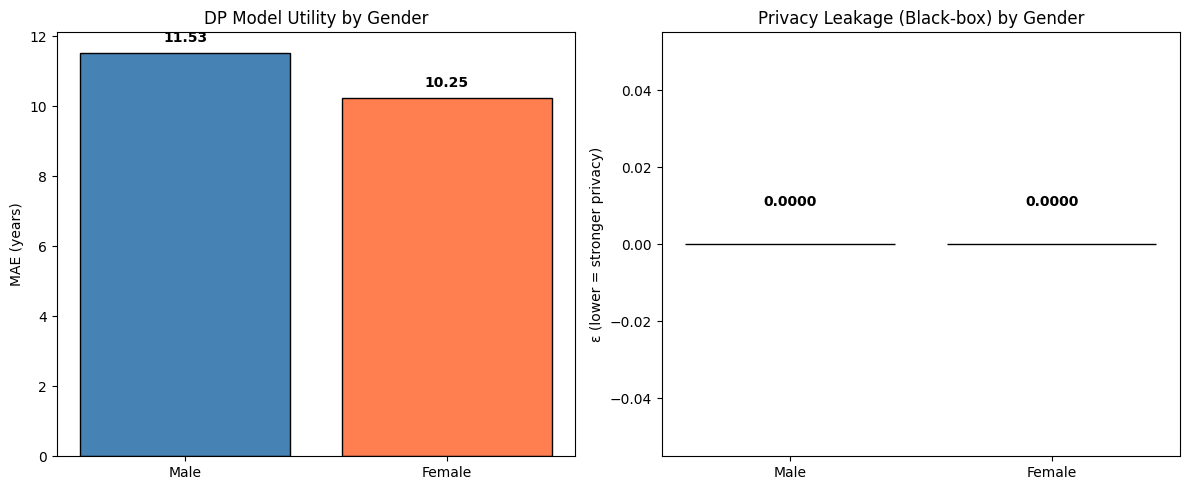


Results saved to project/experiments/gender_bias/


In [10]:
print("\n" + "="*60)
print("GENDER BIAS ANALYSIS - FINAL RESULTS")
print("="*60)

print(f"\n{'Metric':<25} {'Male':<15} {'Female':<15} {'Difference':<15}")
print("-"*70)

for metric in ["dp_mae", "dp_epsilon", "blackbox_epsilon", "whitebox_epsilon"]:
    male_val = male_results[metric]
    female_val = female_results[metric]
    diff = male_val - female_val
    print(f"{metric:<25} {male_val:<15.4f} {female_val:<15.4f} {diff:+15.4f}")

print("\n" + "-"*60)
print("INTERPRETATION")
print("-"*60)

mae_diff = abs(male_results["dp_mae"] - female_results["dp_mae"])
eps_diff = abs(male_results["blackbox_epsilon"] - female_results["blackbox_epsilon"])

if mae_diff < 1.0:
    print("✓ No significant utility bias detected (MAE difference < 1 year)")
else:
    print(f"⚠ Potential utility bias: {mae_diff:.2f} years difference")

if eps_diff < 0.05:
    print("✓ No significant privacy bias detected (ε difference < 0.05)")
else:
    print(f"⚠ Potential privacy bias: ε difference = {eps_diff:.4f}")

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Utility
axes[0].bar(["Male", "Female"], [male_results["dp_mae"], female_results["dp_mae"]], 
            color=['steelblue', 'coral'], edgecolor='black')
axes[0].set_ylabel("MAE (years)")
axes[0].set_title("DP Model Utility by Gender")
for i, val in enumerate([male_results["dp_mae"], female_results["dp_mae"]]):
    axes[0].text(i, val + 0.3, f"{val:.2f}", ha='center', fontweight='bold')

# Privacy
axes[1].bar(["Male", "Female"], [male_results["blackbox_epsilon"], female_results["blackbox_epsilon"]],
            color=['steelblue', 'coral'], edgecolor='black')
axes[1].set_ylabel("ε (lower = stronger privacy)")
axes[1].set_title("Privacy Leakage (Black-box) by Gender")
for i, val in enumerate([male_results["blackbox_epsilon"], female_results["blackbox_epsilon"]]):
    axes[1].text(i, val + 0.01, f"{val:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(CFG["exp_dir"] / "gender_comparison.png", dpi=120)
plt.show()

print(f"\nResults saved to {CFG['exp_dir']}/")

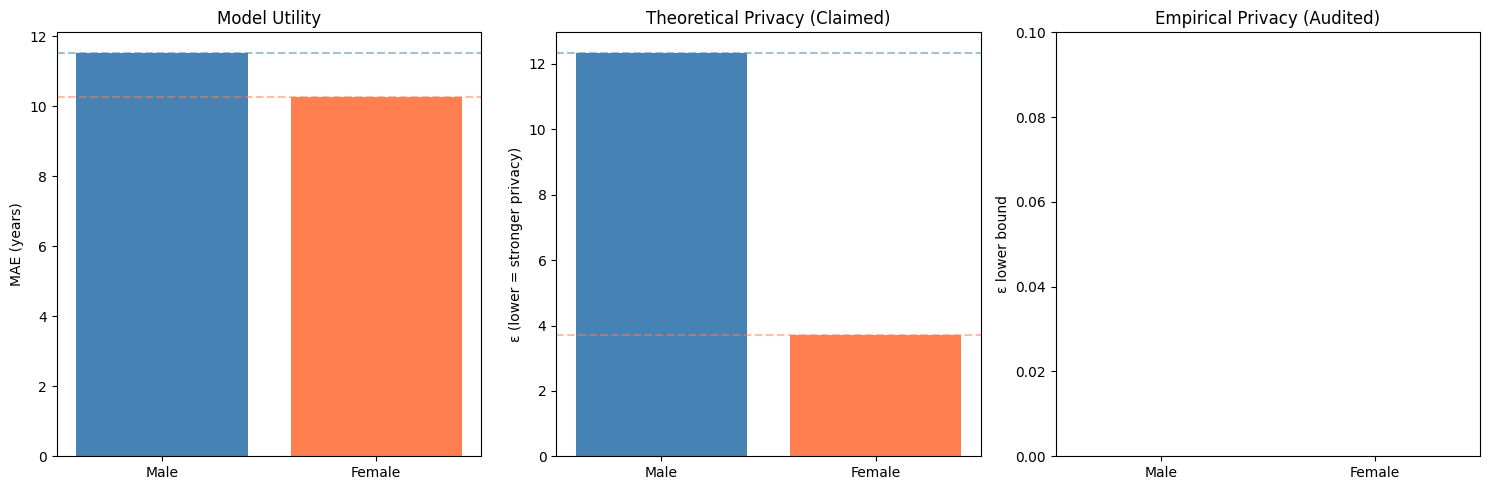

In [11]:
# Create comparison plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Utility
axes[0].bar(['Male', 'Female'], [11.53, 10.25], color=['steelblue', 'coral'])
axes[0].set_ylabel('MAE (years)')
axes[0].set_title('Model Utility')
axes[0].axhline(y=11.53, color='steelblue', linestyle='--', alpha=0.5)
axes[0].axhline(y=10.25, color='coral', linestyle='--', alpha=0.5)

# Privacy (claimed ε)
axes[1].bar(['Male', 'Female'], [12.35, 3.70], color=['steelblue', 'coral'])
axes[1].set_ylabel('ε (lower = stronger privacy)')
axes[1].set_title('Theoretical Privacy (Claimed)')
axes[1].axhline(y=12.35, color='steelblue', linestyle='--', alpha=0.5)
axes[1].axhline(y=3.70, color='coral', linestyle='--', alpha=0.5)

# Privacy (audited)
axes[2].bar(['Male', 'Female'], [0.0, 0.0], color=['steelblue', 'coral'])
axes[2].set_ylabel('ε lower bound')
axes[2].set_title('Empirical Privacy (Audited)')
axes[2].set_ylim(0, 0.1)

plt.tight_layout()
plt.savefig(CFG["exp_dir"] / "gender_bias_summary.png", dpi=150)
plt.show()